## jeu 1
Ici je présenterai le premier jeu de données, et répondrai aux questions joint en ordre. Les visualisation pertinentes seront présenté ainsi.

Commencons par charger les données.

In [1]:
import pandas as pd

df = pd.read_csv('plateforme_apprentissage.csv')
df

,id_apprenant,methode,niveau_initial,score_final,reussite,age,region,heures_etude
0,AP0001,B,intermédiaire,70.6,1,38,Québec,28.1
1,AP0002,B,débutant,52.5,0,32,Outaouais,21.9
2,AP0003,A,avancé,56.2,0,21,Hors Québec,23.5
3,AP0004,A,avancé,70.5,1,36,Outaouais,17.8
4,AP0005,B,débutant,81.7,1,33,Québec,29.3
...,...,...,...,...,...,...,...,...
2395,AP2396,B,débutant,49.3,0,39,Hors Québec,26.8
2396,AP2397,B,débutant,83.7,1,42,Montréal,22.9
2397,AP2398,A,intermédiaire,51.5,0,19,Hors Québec,22.8
2398,AP2399,B,débutant,51.1,0,26,Outaouais,18.3


### Passerelle vers le rapport LaTeX

Tout chiffre cité dans le rapport sort d'ici. On l'enregistre avec `val()`
ou `pct()`, puis `ecrire_valeurs()` les dépose dans `resultats/valeurs.tex`,
que le `.tex` relit à chaque compilation via `\val{clé}`. Les tableaux
passent par `ecrire_tableau()` et se chargent avec `\tbl{nom}`.

Aucun nombre n'est donc recopié à la main dans le rapport : il suffit de
réexécuter le notebook pour que le PDF suive.


In [2]:
from pathlib import Path

DOSSIER_RESULTATS = Path("resultats")
DOSSIER_RESULTATS.mkdir(exist_ok=True)

_valeurs = {}


def val(cle, valeur, dec=1, unite=""):
    """Enregistre un chiffre destiné au rapport et le renvoie inchangé."""
    if isinstance(valeur, str):
        texte = valeur
    elif dec == 0:
        texte = f"{round(valeur):d}"
    else:
        texte = f"{valeur:.{dec}f}".replace(".", ",")  # virgule décimale
    # Un « - » de clavier est un trait d'union : mauvais glyphe, et LaTeX
    # y autorise une coupure de ligne. On impose le vrai signe moins.
    if texte.startswith("-"):
        texte = "$-$" + texte[1:]
    _valeurs[cle.replace("_", "-")] = texte + unite
    return valeur


def pct(cle, proportion, dec=1):
    """Idem, pour une proportion entre 0 et 1 rendue en pourcentage."""
    return val(cle, 100 * proportion, dec=dec, unite=r"\,\%")


def ecrire_valeurs(nom="valeurs.tex"):
    """Écrit toutes les valeurs enregistrées dans resultats/valeurs.tex."""
    chemin = DOSSIER_RESULTATS / nom
    lignes = ["% Généré par le notebook -- ne pas éditer à la main.\n"]
    for cle, texte in sorted(_valeurs.items()):
        lignes.append(f"\\expandafter\\gdef\\csname val@{cle}\\endcsname{{{texte}}}\n")
    chemin.write_text("".join(lignes), encoding="utf-8")
    print(f"{len(_valeurs)} valeurs écrites dans {chemin}")


def ecrire_tableau(nom, tableau, **kwargs):
    """Dépose un tableau LaTeX (booktabs) que le rapport charge via \\tbl{nom}."""
    chemin = DOSSIER_RESULTATS / f"{nom.replace('_', '-')}.tex"
    kwargs.setdefault("float_format", "%.1f")
    chemin.write_text(tableau.to_latex(**kwargs), encoding="utf-8")
    print(f"tableau écrit dans {chemin}")


### Q1 Comparez le taux de réussite global des deux méthodes. Laquelle recommanderiez-vous à la direction de la plateforme?

Pour ceci nous allons séparer les deux méthodes, et trouver les taux de réussite pour chacune.
Je vais commencer par verifier que methode et reussite n'ont pas de nuls, ou valeurs abérantes/éronnées.
Ensuite je vais faire 2 DF, DF_A et DF_B.
En calculant la moyenne, nous aurons le taux de réussite.

In [3]:
df.methode.value_counts(dropna=False)

methode
B    1200
A    1200
Name: count, dtype: int64

In [4]:
df.reussite.value_counts(dropna=False)

reussite
1    1385
0    1015
Name: count, dtype: int64

In [5]:
df_a=df[df['methode'] == 'A']
df_b=df[df['methode'] == 'B']
taux_a= df_a.reussite.mean()
taux_b= df_b.reussite.mean()
print(f"le taux de réussite pour la méthode A est de {taux_a:.2%}")
print(f"le taux de réussite pour la méthode B est de {taux_b:.2%}")

le taux de réussite pour la méthode A est de 70.33%
le taux de réussite pour la méthode B est de 45.08%


In [6]:
# Les chiffres de Q1 partent vers le rapport.
pct("jeu1-taux-a", taux_a)
pct("jeu1-taux-b", taux_b)
val("jeu1-n-a", len(df_a), dec=0)
val("jeu1-n-b", len(df_b), dec=0)
val("jeu1-ecart", abs(100 * (taux_b - taux_a)), dec=1, unite=r"\,points")

ecrire_valeurs()


5 valeurs écrites dans resultats/valeurs.tex


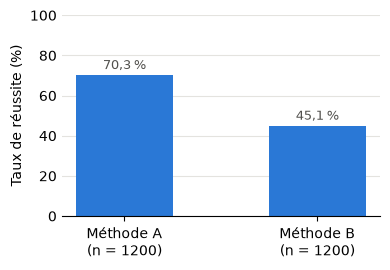

In [7]:
# [IA] Code généré par Claude : figure du taux de réussite par méthode (jeu 1, Q1)
# Figure Q1 : taux de réussite (en %) pour chaque méthode.
import matplotlib.pyplot as plt

DOSSIER_FIGURES = Path("figures")
DOSSIER_FIGURES.mkdir(exist_ok=True)

methodes = ["A", "B"]
groupes = [df_a, df_b]
part_reussite = [100 * g.reussite.mean() for g in groupes]

fig, ax = plt.subplots(figsize=(4, 2.8))
barres = ax.bar([f"Méthode {m}\n(n = {len(g)})" for m, g in zip(methodes, groupes)],
                part_reussite, width=0.5, color="#2a78d6")

# Pourcentage au-dessus de chaque barre, avec virgule décimale.
ax.bar_label(barres, labels=[f"{h:.1f} %".replace(".", ",") for h in barres.datavalues],
             padding=2, fontsize=9, color="#52514e")

ax.set_ylabel("Taux de réussite (%)")
ax.set_ylim(0, 100)
ax.grid(axis="y", color="#e4e3df", linewidth=0.8)
ax.set_axisbelow(True)
for cote in ("top", "right", "left"):
    ax.spines[cote].set_visible(False)
ax.tick_params(axis="y", length=0)

fig.tight_layout()
fig.savefig(DOSSIER_FIGURES / "jeu1_reussite.pdf")
plt.show()

### Q2 Reprenez la même comparaison à l’intérieur de chaque niveau initial. Présentez le résultat sous forme de tableau.

ici nous allons séparé les niveau, et le taux de réussite par niveau.
Ceci permettera d'avoir un meilleur apperçu de chaque méthode.
On veut voir le moyenne des résultats par niveau initial.
Par exemple, on pourrait s'attendre a ce que le niveau avancé ai un meilleur taux de réusite toujours.

In [8]:

results_by_level = df.groupby(["niveau_initial", "methode"])["reussite"].agg(["mean","count"]).unstack()

# results_by_level.columns= [f"{stat} {methode}" for stat, methode in results_by_level.columns]
# arrondir et %
# for meth in ["A", "B"]:
results_by_level['mean']=round(results_by_level["mean"]*100, 1)
    # results_by_level.drop(columns=[f"mean {meth}"], inplace=True)


results_by_level.rename_axis("Niveau initial", inplace=True)
results_by_level.rename(columns={"mean": "Moyenne", "count": "Compte"}, inplace=True)

ecrire_tableau("jeu1-Q1",results_by_level)

results_by_level

tableau écrit dans resultats/jeu1-Q1.tex


Moyenne       Compte     
methode              A     B      A    B
Niveau initial                          
avancé            80.6  93.3    930   90
débutant          16.7  36.0     90  930
intermédiaire     43.9  67.8    180  180

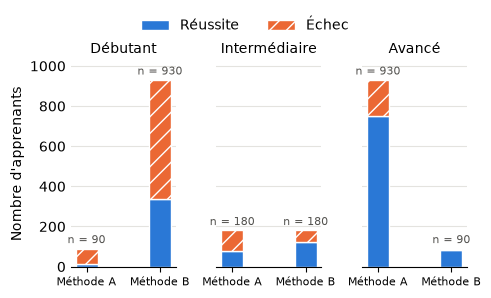

In [9]:
# [IA] Code généré par Claude : figure réussite / échec par méthode et par niveau (jeu 1, Q2)
# Un panneau par niveau initial ; dans chaque panneau, une barre par méthode,
# empilée en réussite (bas) et échec (haut). Hauteur totale = effectif.
niveaux = ["débutant", "intermédiaire", "avancé"]
comptes = pd.crosstab([df.niveau_initial, df.methode], df.reussite)

fig, axes = plt.subplots(1, len(niveaux), figsize=(5, 3), sharey=True)
for ax, niveau in zip(axes, niveaux):
    reussis = [comptes.loc[(niveau, m), 1] for m in methodes]
    echecs = [comptes.loc[(niveau, m), 0] for m in methodes]
    totaux = [r + e for r, e in zip(reussis, echecs)]

    ax.bar(methodes, reussis, width=0.3, color="#2a78d6", label="Réussite",
           edgecolor="white", linewidth=1)
    ax.bar(methodes, echecs, width=0.3, bottom=reussis, color="#eb6834", hatch="//",
           label="Échec", edgecolor="white", linewidth=1)

    # Effectif total au-dessus de chaque barre.
    for x, n in zip(methodes, totaux):
        ax.annotate(f"n = {n}", (x, n), xytext=(0, 2), textcoords="offset points",
                    ha="center", va="bottom", fontsize=8, color="#52514e")

    ax.set_title(niveau.capitalize(), fontsize=10)
    ax.set_xticks(range(len(methodes)), [f"Méthode {m}" for m in methodes], fontsize=8)
    ax.grid(axis="y", color="#e4e3df", linewidth=0.8)
    ax.set_axisbelow(True)
    for cote in ("top", "right", "left"):
        ax.spines[cote].set_visible(False)
    ax.tick_params(axis="y", length=0)

axes[0].set_ylabel("Nombre d'apprenants")
axes[0].set_ylim(0, 1.1 * comptes.sum(axis=1).max())
poignees, etiquettes = axes[0].get_legend_handles_labels()
fig.legend(poignees, etiquettes, loc="upper center", ncols=2, frameon=False,
           bbox_to_anchor=(0.5, 1.0))

fig.tight_layout(rect=(0, 0, 1, 0.92))
fig.savefig(DOSSIER_FIGURES / "jeu1_niveau.pdf")
plt.show()

### Q4  Recalculez un taux global pour chaque méthode, en pondérant cette fois les taux par niveau par les effectifs de l’ensemble du groupe, et non par ceux de chaque méthode. Quelle méthode recommandez-vous au terme de votre analyse?

En pondérant les taux globaux selon le nombre d'éffectifs, la différence de 840 entre les méthodes pour avancé et débutant sera corrigé.
Ceci donnera une moyenne global de chaque méthode non biaisé par les niveau de départ.


In [10]:
results_by_level['Compte total'] = results_by_level['Compte'].sum(axis=1)
results_by_level["Moyenne B Pondérée"]= results_by_level["Moyenne"]["B"]*results_by_level["Compte total"]/results_by_level["Compte total"].sum()
mean_b_adjusted=results_by_level["Moyenne B Pondérée"].sum()
results_by_level["Moyenne A Pondérée"]= results_by_level["Moyenne"]["A"]*results_by_level["Compte total"]/results_by_level["Compte total"].sum()
mean_a_adjusted=results_by_level["Moyenne A Pondérée"].sum()
print(f"le taux de réussite pondéré pour la méthode A est de {mean_a_adjusted}")
print(f"le taux de réussite pondéré pour la méthode B est de {mean_b_adjusted}")

le taux de réussite pondéré pour la méthode A est de 47.93750000000001
le taux de réussite pondéré pour la méthode B est de 65.1225


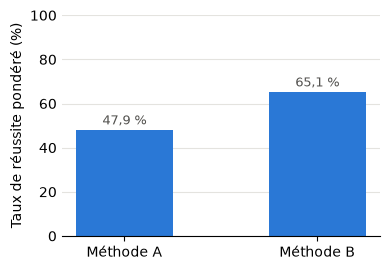

In [11]:
# [IA] Code généré par Claude : figure du taux de réussite pondéré par méthode (jeu 1, Q4)
# Même présentation que la figure Q1, avec les taux pondérés par les effectifs du groupe.
taux_ponderes = [mean_a_adjusted, mean_b_adjusted]

fig, ax = plt.subplots(figsize=(4, 2.8))
barres = ax.bar([f"Méthode {m}" for m in methodes], taux_ponderes, width=0.5, color="#2a78d6")

# Pourcentage au-dessus de chaque barre, avec virgule décimale.
ax.bar_label(barres, labels=[f"{h:.1f} %".replace(".", ",") for h in barres.datavalues],
             padding=2, fontsize=9, color="#52514e")

ax.set_ylabel("Taux de réussite pondéré (%)")
ax.set_ylim(0, 100)
ax.grid(axis="y", color="#e4e3df", linewidth=0.8)
ax.set_axisbelow(True)
for cote in ("top", "right", "left"):
    ax.spines[cote].set_visible(False)
ax.tick_params(axis="y", length=0)

fig.tight_layout()
fig.savefig(DOSSIER_FIGURES / "jeu1_reussite_ponderee.pdf")
plt.show()

### Q5 Reprenez la démarche de la question 2 avec l’une des colonnes age, region ou heures_etude. Comparez ce que vous obtenez avec le résultat de la question 2 et commentez.

Nous allons le répété avec région, car il n'a que 4 régions.

In [12]:
results_by_region = df.groupby(["region", "methode"])["reussite"].agg(["mean","count"]).unstack()

# results_by_level.columns= [f"{stat} {methode}" for stat, methode in results_by_level.columns]
# arrondir et %
# for meth in ["A", "B"]:
results_by_region['mean']=round(results_by_region["mean"]*100, 1)
    # results_by_level.drop(columns=[f"mean {meth}"], inplace=True)


results_by_region.rename_axis("region", inplace=True)
results_by_region.rename(columns={"mean": "Moyenne", "count": "Compte"}, inplace=True)



results_by_region

Moyenne       Compte     
methode           A     B      A    B
region                               
Hors Québec    69.5  44.0    341  309
Montréal       68.2  46.5    302  303
Outaouais      69.5  44.9    282  263
Québec         74.5  44.9    275  325

In [13]:
# [IA] Code généré par Claude : export du tableau par région vers le rapport (jeu 1, Q5)
ecrire_tableau("jeu1-Q5", results_by_region)

tableau écrit dans resultats/jeu1-Q5.tex


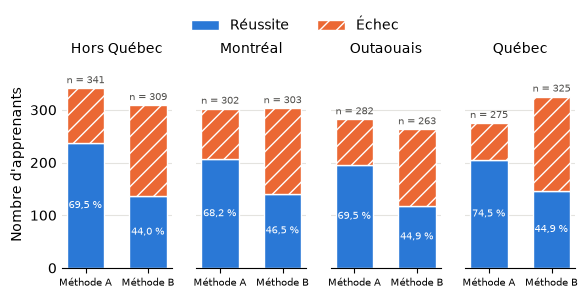

In [14]:
# [IA] Code généré par Claude : figure réussite / échec par méthode et par région (jeu 1, Q5)
# Même présentation que la figure Q2 : un panneau par région ; dans chaque panneau,
# une barre par méthode, empilée en réussite (bas) et échec (haut). Hauteur totale = effectif.
regions = sorted(df.region.unique())
comptes_region = pd.crosstab([df.region, df.methode], df.reussite)

fig, axes = plt.subplots(1, len(regions), figsize=(6, 3), sharey=True)
for ax, region in zip(axes, regions):
    reussis = [comptes_region.loc[(region, m), 1] for m in methodes]
    echecs = [comptes_region.loc[(region, m), 0] for m in methodes]
    totaux = [r + e for r, e in zip(reussis, echecs)]

    barres_reussite = ax.bar(methodes, reussis, width=0.6, color="#2a78d6", label="Réussite",
                             edgecolor="white", linewidth=1)
    ax.bar(methodes, echecs, width=0.6, bottom=reussis, color="#eb6834", hatch="//",
           label="Échec", edgecolor="white", linewidth=1)

    # Taux de réussite (%) au centre de la partie réussite, avec virgule décimale.
    ax.bar_label(barres_reussite,
                 labels=[f"{100 * r / t:.1f} %".replace(".", ",") for r, t in zip(reussis, totaux)],
                 label_type="center", fontsize=7, color="white")

    # Effectif total au-dessus de chaque barre.
    for x, n in zip(methodes, totaux):
        ax.annotate(f"n = {n}", (x, n), xytext=(0, 2), textcoords="offset points",
                    ha="center", va="bottom", fontsize=7, color="#52514e")

    ax.set_title(region, fontsize=10)
    ax.set_xticks(range(len(methodes)), [f"Méthode {m}" for m in methodes], fontsize=7)
    ax.grid(axis="y", color="#e4e3df", linewidth=0.8)
    ax.set_axisbelow(True)
    for cote in ("top", "right", "left"):
        ax.spines[cote].set_visible(False)
    ax.tick_params(axis="y", length=0)

axes[0].set_ylabel("Nombre d'apprenants")
axes[0].set_ylim(0, 1.15 * comptes_region.sum(axis=1).max())
poignees, etiquettes = axes[0].get_legend_handles_labels()
fig.legend(poignees, etiquettes, loc="upper center", ncols=2, frameon=False,
           bbox_to_anchor=(0.5, 1.0))

fig.tight_layout(rect=(0, 0, 1, 0.92))
fig.savefig(DOSSIER_FIGURES / "jeu1_region.pdf")
plt.show()

## Jeu 2 -  consommation électrique d’un immeuble de bureaux

Suite pour jeu deux cette fois.

Chargons les données.

In [15]:
df_j2=pd.read_csv('consommation_batiment.csv')
df_j2

,date,jour_semaine,jour_ferie,temperature_c,occupation_pct,consommation_kwh
0,2023-01-01,dimanche,1,8.5,16.7,572.1
1,2023-01-02,lundi,0,1.6,67.1,1172.2
2,2023-01-03,mardi,0,6.7,72.2,954.8
3,2023-01-04,mercredi,0,4.2,69.0,943.4
4,2023-01-05,jeudi,0,3.7,74.1,1065.7
...,...,...,...,...,...,...
1090,2025-12-26,vendredi,1,7.4,12.0,764.9
1091,2025-12-27,samedi,0,2.7,18.9,826.1
1092,2025-12-28,dimanche,0,8.0,7.3,578.0
1093,2025-12-29,lundi,0,3.6,88.3,1079.1


In [16]:
df_j2.describe()

,jour_ferie,temperature_c,occupation_pct,consommation_kwh
count,1095.000000,1095.000000,1095.000000,1095.000000
mean,0.013699,15.450502,52.966849,854.081735
std,0.116290,9.123651,28.042341,244.460953
min,0.000000,-4.400000,2.000000,250.400000
25%,0.000000,7.200000,15.900000,679.700000
50%,0.000000,15.700000,65.800000,860.300000
75%,0.000000,23.700000,73.550000,1033.800000
max,1.000000,35.600000,97.800000,1679.100000


In [17]:
df_j2.isna().sum()

date                0
jour_semaine        0
jour_ferie          0
temperature_c       0
occupation_pct      0
consommation_kwh    0
dtype: int64

### Q1 Calculez le coefficient de corrélation entre la température extérieure et la consommation. Interprétez cette valeur en une phrase.

Aucun nuls, aucun max ou min qui semble aberant rapidement.

validons le coefficient de corrélation

In [18]:
correlation_coef= float(df_j2["consommation_kwh"].corr(df_j2["temperature_c"]))

val('correlation_coef', correlation_coef, dec=4)
ecrire_valeurs()
correlation_coef

6 valeurs écrites dans resultats/valeurs.tex


0.011862263776120653

### Q2 Tracez le nuage de points de la consommation en fonction de la température. Décrivez la forme obtenue et commentez-la au regard de la valeur calculée à la question 1.

Tracons un nuage de points de la corrélation entre les deux variable.
Avec le résultat de l'étape 1, on peut s'attendre a ce que les deux variable n'ont aucune corrélation.


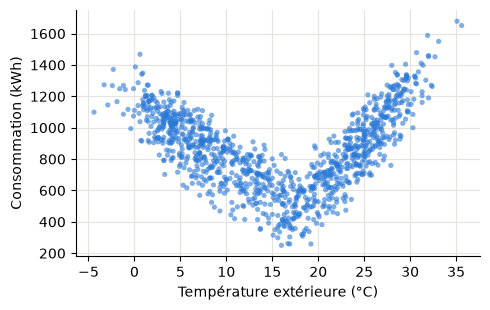

In [19]:
# [IA] Code généré par Claude : nuage de points consommation / température (jeu 2, Q2)
# Un point par jour : température extérieure en abscisse, consommation en ordonnée.
fig, ax = plt.subplots(figsize=(5, 3.2))
ax.scatter(df_j2["temperature_c"], df_j2["consommation_kwh"],
           s=14, color="#2a78d6", alpha=0.6, edgecolors="none")

ax.set_xlabel("Température extérieure (°C)")
ax.set_ylabel("Consommation (kWh)")
ax.grid(color="#e4e3df", linewidth=0.8)
ax.set_axisbelow(True)
for cote in ("top", "right"):
    ax.spines[cote].set_visible(False)

fig.tight_layout()
fig.savefig(DOSSIER_FIGURES / "jeu2_nuage_conso_temperature.pdf")
plt.show()


### Q3 Séparez les journées en deux groupes selon un seuil de température que vous choisirez et justifierez. Calculez le coefficient de corrélation dans chacun des deux groupes et comparez avec la question 1.

Au lieu de choisir une valeur, je vais testé les valeurs entre 15 et 20, et voir ou les coefficients se stabilise. 
On veut avoir un coefficient des deux sections qui sont maximales.
Selon les données, il y a surement plus d'une valeur qui donnera des coeficients similaires

In [22]:
upper_limit=20
limit=15

while limit<=upper_limit:
    df_temp_test=pd.DataFrame()
    masque= df_j2["temperature_c"]<limit
    df_temp_test.cold=df_j2[masque]
    df_temp_test.hot=df_j2[~masque]

    limit+=.1




/tmp/ipykernel_13687/2504568385.py:7: UserWarning: Pandas doesn't allow columns to be created via a new attribute name - see https://pandas.pydata.org/pandas-docs/stable/indexing.html#attribute-access
  df_temp_test.cold=df_j2[masque]
/tmp/ipykernel_13687/2504568385.py:8: UserWarning: Pandas doesn't allow columns to be created via a new attribute name - see https://pandas.pydata.org/pandas-docs/stable/indexing.html#attribute-access
  df_temp_test.hot=df_j2[~masque]
/tmp/ipykernel_13687/2504568385.py:7: UserWarning: Pandas doesn't allow columns to be created via a new attribute name - see https://pandas.pydata.org/pandas-docs/stable/indexing.html#attribute-access
  df_temp_test.cold=df_j2[masque]
/tmp/ipykernel_13687/2504568385.py:8: UserWarning: Pandas doesn't allow columns to be created via a new attribute name - see https://pandas.pydata.org/pandas-docs/stable/indexing.html#attribute-access
  df_temp_test.hot=df_j2[~masque]
/tmp/ipykernel_13687/2504568385.py:7: UserWarning: Pandas do